# The IAEA artefact

> The broad shift of the IAEA Thermo spectra: its shape, how it varies between operators, whether it harms the predictions, and whether removing it helps

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspecdata.datasets.ringtrial import load_ringtrial
from soilspecdl.all import get_splitter, group_folds, predict, regression_scores
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import preprocessings, load_pretrained
from ossl_fuku_transfer.grouped import oof_preds
from ossl_fuku_transfer.epo import epo_project
from ossl_fuku_transfer.inside import layer_features

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


The cells that read the Fukushima data are marked `#| fukudata` and `#| rtdata`, because they read the Fukushima data and the ring trial. The outputs on this page come from a local run.

After SNV, the Thermo spectra of the Fukushima soils are higher than their OSSL analogues at 2800–3700 cm⁻¹ and lower below 2000 cm⁻¹ (`16_moisture`). `ossl-rt-transfer/10_where_it_fails` found the same shift in the ring-trial scans of the IAEA Nicolet, on soils that Woodwell prepared centrally, and on almost every soil. This notebook measures the shift on the Fukushima soils that both instruments scanned, finds what its strength depends on, and tests whether it harms the predictions and whether removing it helps.

The OSSL models also fail on the Bruker spectra of the same soils (`05_paired`). A correction of the Thermo spectra can therefore at most bring the predictions to the Bruker level. The tests report that ceiling.

## The artefact

All spectra on the 2 cm⁻¹ grid from 650 to 3996 cm⁻¹, the range of the Bruker exports, with SNV. The artefact profile is the mean difference between the Thermo and Bruker spectra of the same soils, and the ring-trial profile the mean difference between the IAEA and KSSL spectra of the 70 ring-trial soils:

In [ ]:
#| fukudata
#| rtdata
pw = shared_wns[:-1]
snv = lambda A: (A - A.mean(1, keepdims=True)) / A.std(1, keepdims=True)
pids = [i for i in sorted(set(bruker_files()) & set(spa_files()), key=int) if i not in excluded]
br, th = load_bruker(pw, pids), load_fuku(pw, pids)
D_tb = snv(th.spectra) - snv(br.spectra)
rt = load_ringtrial(data_path()/'ringtrial')
rt_ids = sorted(set(rt['IAEA_aug2022'].sample_ids) & set(rt['KSSL'].sample_ids))
def on(sp, ids): return sp.spectra[pd.Index(sp.sample_ids).get_indexer(ids)][:, np.isin(sp.wavenumbers, pw)]
Ria, Rks = on(rt['IAEA_aug2022'], rt_ids), on(rt['KSSL'], rt_ids)
D_rt = snv(Ria) - snv(Rks)
p_tb, p_rt = D_tb.mean(0), D_rt.mean(0)
len(pids), len(rt_ids), np.corrcoef(p_tb, p_rt)[0, 1].round(3)

(376, 70, np.float64(0.872))

In [ ]:
#| fukudata
#| rtdata
regions = {'650–1300': (650, 1300), '1300–1610': (1300, 1610), 'H–O–H bend 1610–1650': (1610, 1650), '1650–2000': (1650, 2000),
           '2000–2800': (2000, 2800), '2800–3200': (2800, 3200), 'O–H stretch 3200–3450': (3200, 3450), '3450–3700': (3450, 3700), '3700–3996': (3700, 3996)}
def by_region(D, f): return pd.Series({k: f(D[:, (pw >= lo) & (pw <= hi)]) for k, (lo, hi) in regions.items()})
pd.DataFrame({'Thermo − Bruker, mean': by_region(D_tb, np.mean), 'share higher': by_region(D_tb, lambda d: (d > 0).mean()),
              'IAEA − KSSL, mean': by_region(D_rt, np.mean), 'share higher ': by_region(D_rt, lambda d: (d > 0).mean())}).round(3)

,"Thermo − Bruker, mean",share higher,"IAEA − KSSL, mean",share higher
650–1300,-1.958,0.002,-0.534,0.104
1300–1610,-0.644,0.001,-0.373,0.105
H–O–H bend 1610–1650,-0.430,0.001,-0.389,0.018
1650–2000,0.058,0.729,-0.065,0.412
2000–2800,0.463,0.952,0.030,0.471
2800–3200,1.013,1.000,0.442,0.996
O–H stretch 3200–3450,1.084,1.000,0.567,1.000
3450–3700,1.111,1.000,0.633,0.994
3700–3996,0.495,0.860,0.002,0.359


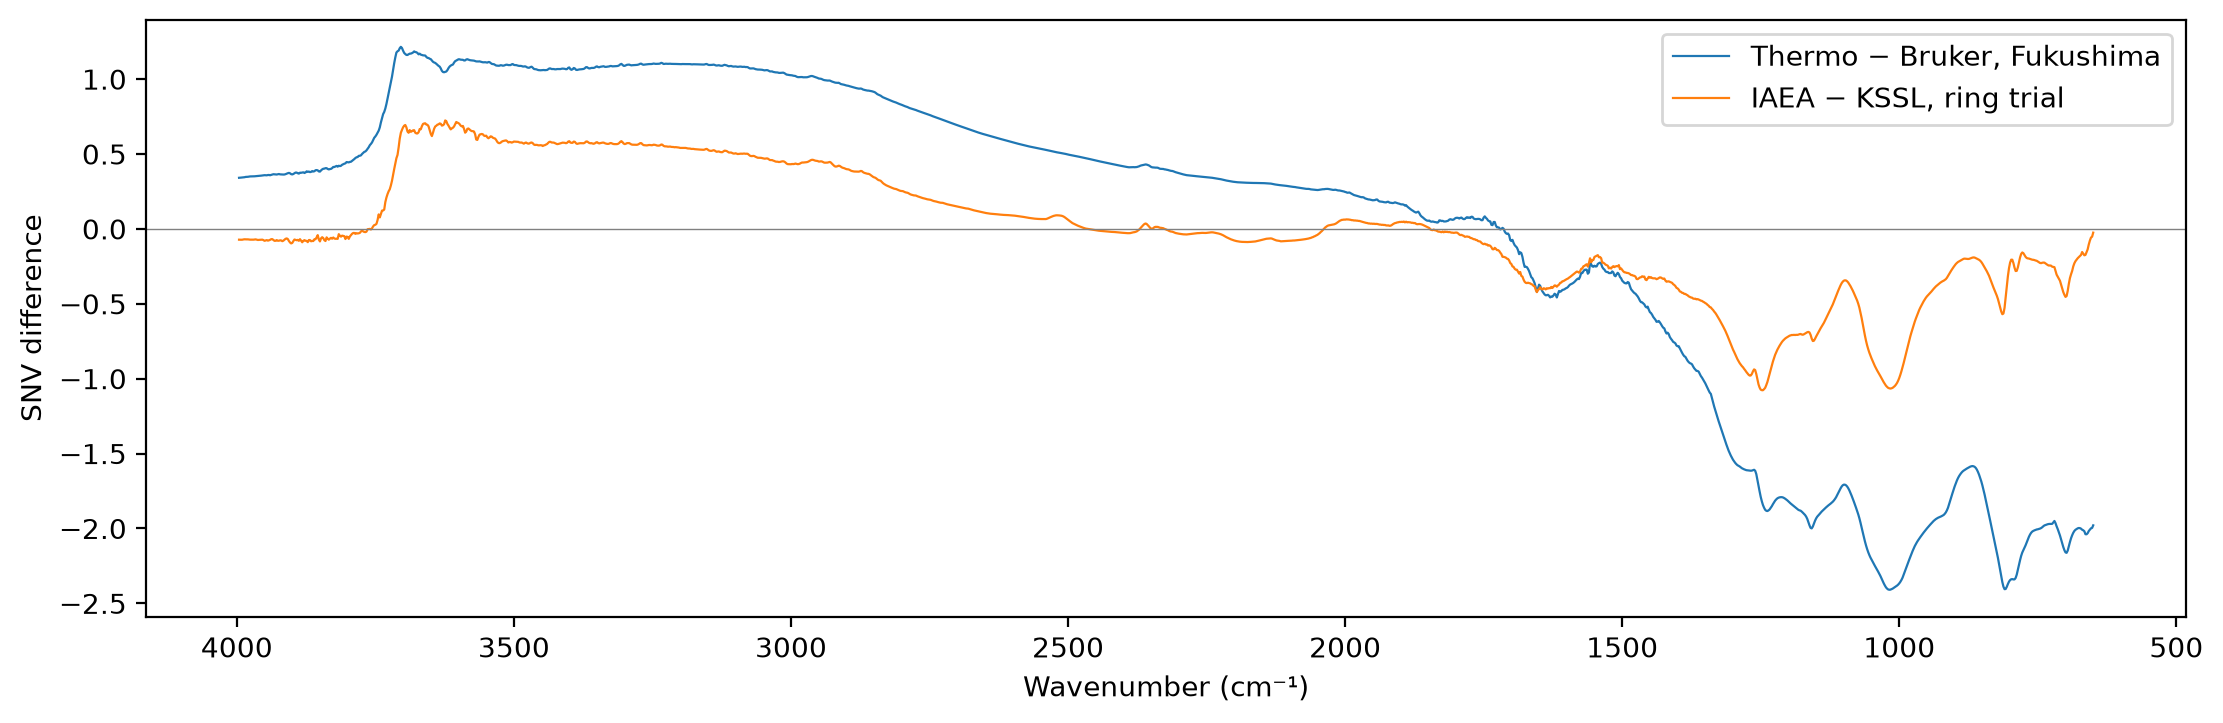

In [ ]:
#| fukudata
#| rtdata
fig, ax = plt.subplots(figsize=(11, 3.5), layout='constrained')
ax.plot(pw, p_tb, lw=0.8, label='Thermo − Bruker, Fukushima'); ax.plot(pw, p_rt, lw=0.8, label='IAEA − KSSL, ring trial')
ax.axhline(0, c='grey', lw=0.5); ax.invert_xaxis(); ax.set_xlabel('Wavenumber (cm⁻¹)'); ax.set_ylabel('SNV difference'); ax.legend();

## Strength by operator

The strength of the artefact in a scan is the least-squares coefficient of its difference from the Bruker spectrum of the same soil on the profile `p_tb`, so the mean strength over the paired soils is 1. The strength of each replicate, against the mean Bruker spectrum of its soil, splits the variation into a part within samples, from loading the cup, and a part between samples:

In [ ]:
#| fukudata
#| rtdata
strength = lambda D: D @ p_tb / (p_tb @ p_tb)
s = strength(D_tb)
reps = load_replicates(pw, pids)
s_rep = pd.Series(strength(snv(reps.spectra) - snv(br.spectra)[pd.Index(br.sample_ids).get_indexer(reps.sample_ids)]), index=reps.sample_ids)
test_close(s.mean(), 1, eps=1e-9)
pd.Series({'within samples': s_rep.groupby(level=0).var().mean(), 'between samples': s_rep.groupby(level=0).mean().var()}, name='variance').round(4)

within samples     0.0029
between samples    0.0667
Name: variance, dtype: float64

`sample_batches` numbers the folders of the Thermo files, one per operator: batch 1 is operator 1's, batch 2 operator 2's and batch 3 operator 3's. The strength by batch, by year of sampling and by soil type, and its Spearman correlation with soil properties. The ring-trial strength uses the same profile:

In [ ]:
#| fukudata
#| rtdata
ops = {'batch 1': 'operator 1', 'batch 2': 'operator 2', 'batch 3': 'operator 3'}
meta = pd.DataFrame({'strength': s, 'operator': pd.Series(sample_batches(pids)).map(ops).values}, index=pids).join(th.source.reindex(pids)[['year', 'Soil_type_describe', 'soil_C', 'soil_CEC', 'clay']])
display(pd.concat({g: meta.groupby(g).strength.agg(['count', 'mean', 'std']) for g in ['operator', 'year']}).round(3))
s_ring = D_rt @ p_tb / (p_tb @ p_tb)
pd.Series({**{f'ρ with {c}': spearmanr(meta.strength, pd.to_numeric(meta[c], errors='coerce'), nan_policy='omit')[0] for c in ['soil_C', 'soil_CEC', 'clay']},
           'ring trial, IAEA, mean strength': s_ring.mean()}).round(3)

count   mean    std
operator operator 1     12  0.317  0.084
         operator 2     48  0.450  0.087
         operator 3    316  1.109  0.057
year     2016.0         14  0.469  0.060
         2017.0         12  0.480  0.075
         2018.0         12  0.317  0.084
         2019.0         11  0.490  0.053
         2020.0         11  0.353  0.089
         2022.0        161  1.092  0.051
         2023.0        155  1.128  0.056

ρ with soil_C                     -0.143
ρ with soil_CEC                    0.010
ρ with clay                        0.084
ring trial, IAEA, mean strength    0.332
dtype: float64

The projection of the Thermo and Bruker spectra on the profile, by operator, shows on which side the difference between operators lies:

In [ ]:
#| fukudata
#| rtdata
proj = lambda S: S @ p_tb / (p_tb @ p_tb)
pd.DataFrame({'Thermo': proj(snv(th.spectra)), 'Bruker': proj(snv(br.spectra)), 'operator': meta.operator.values}).groupby('operator').agg(['mean', 'std']).round(3)

Thermo        Bruker       
             mean    std   mean    std
operator                              
operator 1 -0.197  0.080 -0.514  0.041
operator 2 -0.123  0.098 -0.573  0.043
operator 3  0.572  0.070 -0.537  0.039

## Strength by scan date

A colleague who measured cassava plants on a similar set-up found that opening the sample chamber from above moved the mirrors, so that the alignment changed between batches. If this happened here, the strength should change between measurement sessions and stay stable within one.

`spa_time` reads the acquisition time from a Thermo `.spa` file, stored at byte 296 as seconds since 31 December 1899, the layout that common `.spa` readers use. The file modification times only record when the files were copied, in October 2026:

In [ ]:
import struct, datetime
def spa_time(fn):
    "Acquisition time of the Thermo `.spa` file `fn`"
    with open(fn, 'rb') as f:
        f.seek(296)
        return datetime.datetime(1899, 12, 31) + datetime.timedelta(seconds=struct.unpack('<I', f.read(4))[0])

The mean strength of the paired soils by scan day, with the standard deviation within each day:

In [ ]:
#| fukudata
#| rtdata
meta['day'] = [spa_time(spa_files()[i][0]).date() for i in meta.index]
display(meta.groupby('operator').day.agg(['min', 'max']))
days = meta.groupby(['operator', 'day']).strength.agg(['count', 'mean', 'std'])
days.round(3)

,min,max
operator,,
operator 1,2023-01-13,2023-01-30
operator 2,2024-06-27,2024-11-22
operator 3,2026-02-26,2026-03-27


count   mean    std
operator   day                            
operator 1 2023-01-13      1  0.260    NaN
           2023-01-16      1  0.362    NaN
           2023-01-18      4  0.343  0.080
           2023-01-26      4  0.332  0.112
           2023-01-30      2  0.242  0.010
operator 2 2024-06-27      1  0.376    NaN
           2024-06-28      3  0.269  0.091
           2024-07-03      1  0.344    NaN
           2024-07-23      1  0.426    NaN
           2024-07-24      2  0.402  0.017
           2024-07-25      2  0.307  0.018
           2024-08-07      1  0.515    NaN
           2024-08-08      1  0.512    NaN
           2024-08-09      3  0.490  0.011
           2024-08-12      1  0.449    NaN
           2024-08-20      1  0.495    NaN
           2024-08-29      4  0.467  0.064
           2024-09-02      1  0.597    NaN
           2024-09-03      1  0.529    NaN
           2024-09-04      1  0.632    NaN
           2024-09-09      2  0.457  0.002
           2024-09-11      3  0.467  0.068
           2024-09-12      4  0.468  0.069
           2024-09-16      1  0.455    NaN
           2024-10-07      1  0.455    NaN
           2024-10-14      3  0.464  0.019
           2024-10-29      3  0.400  0.060
           2024-10-30      1  0.464    NaN
           2024-11-07      2  0.563  0.052
           2024-11-20      2  0.439  0.017
           2024-11-22      2  0.507  0.089
operator 3 2026-02-26      6  1.092  0.030
           2026-03-03     21  1.103  0.046
           2026-03-04     11  1.091  0.050
           2026-03-05     10  1.122  0.031
           2026-03-06     17  1.096  0.051
           2026-03-09     18  1.092  0.054
           2026-03-10     11  1.070  0.045
           2026-03-11     23  1.076  0.048
           2026-03-12      8  1.045  0.054
           2026-03-16     33  1.100  0.056
           2026-03-17     23  1.112  0.045
           2026-03-18     20  1.172  0.042
           2026-03-19     20  1.164  0.039
           2026-03-23     29  1.114  0.041
           2026-03-24     23  1.154  0.046
           2026-03-25     19  1.113  0.058
           2026-03-26     15  1.085  0.071
           2026-03-27      9  1.072  0.041

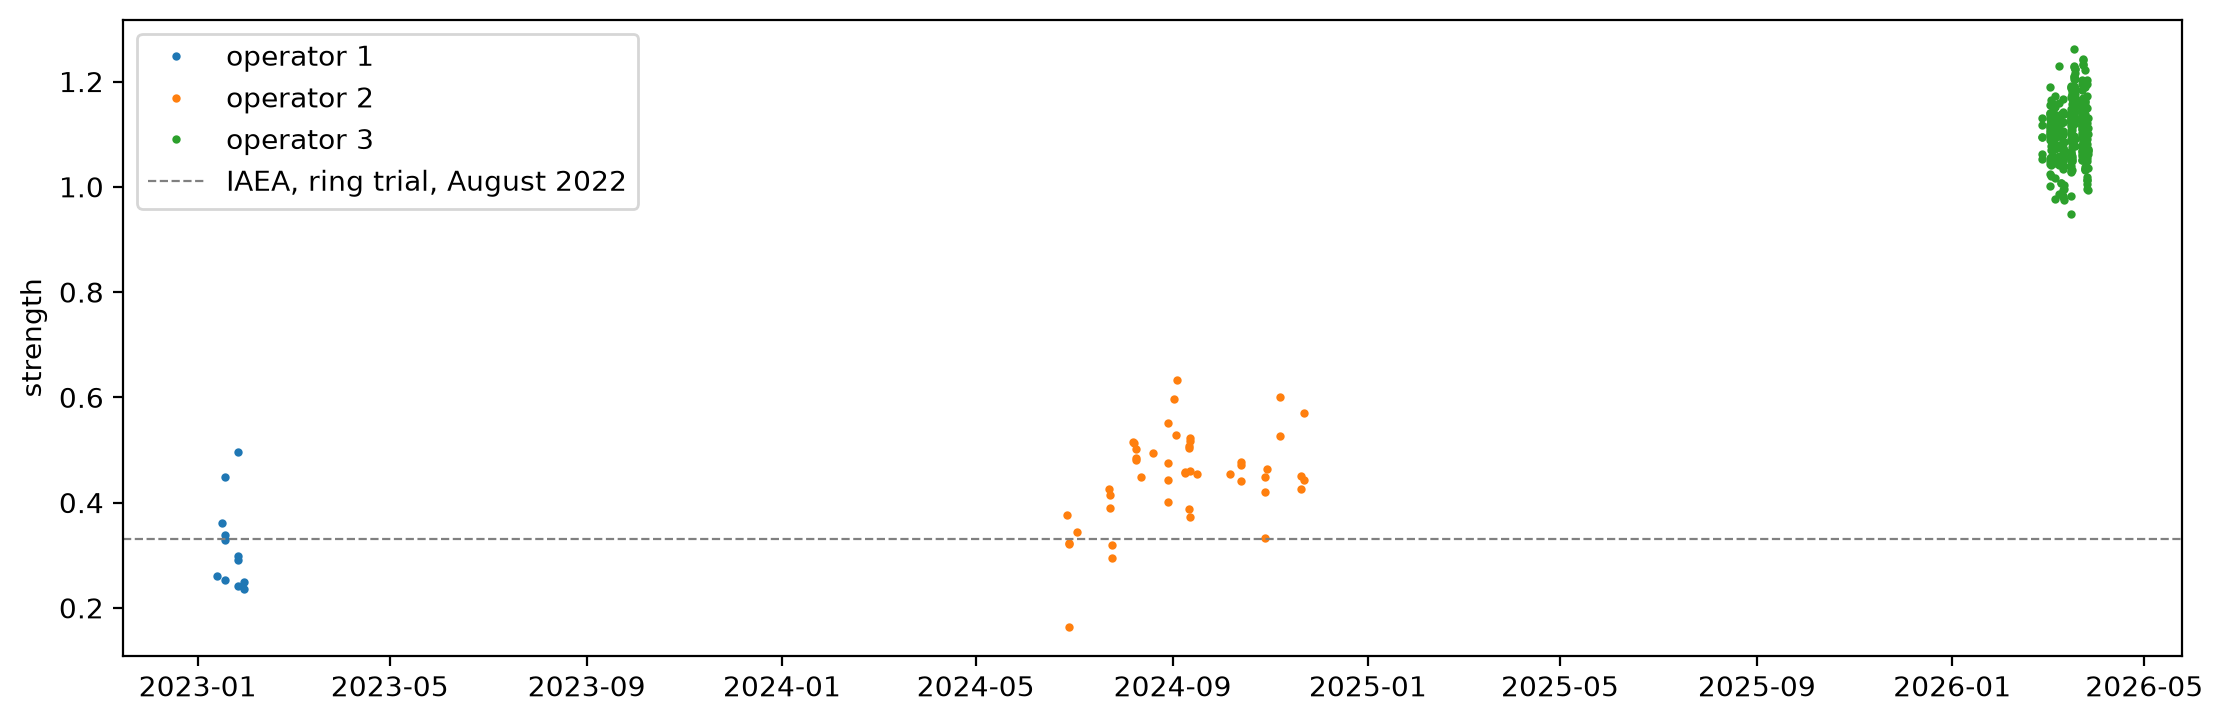

In [ ]:
#| fukudata
#| rtdata
fig, ax = plt.subplots(figsize=(11, 3.5), layout='constrained')
for o, d in meta.groupby('operator'): ax.plot(pd.to_datetime(d.day), d.strength, '.', ms=4, label=o)
ax.axhline(s_ring.mean(), c='grey', ls='--', lw=0.8, label='IAEA, ring trial, August 2022')
ax.set_ylabel('strength'); ax.legend();

The 1,389 samples used for modelling come from operator 1's and operator 2's folders only:

In [ ]:
#| fukudata
#| rtdata
fuku = load_fuku()
ids = fuku.sample_ids
op_f = pd.Series(sample_batches(ids)).map(ops).values
pd.Series(op_f).value_counts()

operator 2    854
operator 1    535
Name: count, dtype: int64

The 1,389 modelling samples have no Bruker spectra. Their projection on the profile mixes the artefact with differences between soils, but its mean over a month of scans follows the artefact:

In [ ]:
#| fukudata
#| rtdata
month = pd.Series([spa_time(spa_files()[i][0]).strftime('%Y-%m') for i in ids])
pd.DataFrame({'operator': op_f, 'month': month, 'projection': proj(snv(fuku.spectra[:, np.isin(shared_wns, pw)]))}).groupby(['operator', 'month']).projection.agg(['count', 'mean', 'std']).round(3)

count   mean    std
operator   month                       
operator 1 2022-12    143 -0.238  0.128
           2023-01    211 -0.245  0.101
           2023-02    165 -0.303  0.089
           2023-03     16 -0.313  0.075
operator 2 2024-06     27 -0.340  0.170
           2024-07     57 -0.284  0.114
           2024-08    202 -0.132  0.105
           2024-09    189 -0.152  0.087
           2024-10     64 -0.151  0.079
           2024-11    129 -0.147  0.095
           2024-12    113 -0.180  0.092
           2025-01     73 -0.192  0.083

## Harm to transfer from OSSL

The artefact added to 2,000 OSSL validation spectra, after SNV and before the derivative, at the mean strength of each operator. The models are the OSSL Kex and CEC models of `03_kex` and `04_cec`, on `log1p` of the property:

In [ ]:
#| fukudata
#| rtdata
pipe = preprocessings()['snv_d1']
deriv = pipe.named_steps['deriv']
pad = lambda A: np.c_[A, A[:, -1:]]
p_full = pad(p_tb[None])[0]
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
models = {'Kex': load_pretrained('ossl_kex_snv_d1'), 'CEC': load_pretrained('ossl_cec_snv_d1')}
cols = {'Kex': 'k.ext_usda.a725_cmolc.kg', 'CEC': 'cec_usda.a723_cmolc.kg'}
s_op = meta.groupby('operator').strength.mean()
def pred(m, S): return predict(models[m], deriv.transform(S), shared_wns).ravel()
rows = {}
for m, c in cols.items():
    Xo, yo, _ = om.xy(c)
    yo = np.log1p(yo.ravel())
    vs = np.random.default_rng(0).choice(get_splitter(0.9, 0.1, seed=42)(Xo, yo)[1], 2000, replace=False)
    So, yv = snv(Xo[vs]), yo[vs]
    p0 = pred(m, So)
    for k, a in {'none': 0, **s_op}.items():
        p = pred(m, So + a * p_full)
        rows[m, k] = {'strength': a, **regression_scores(yv, p), 'RMS change': np.sqrt(((p - p0)**2).mean())}
pd.DataFrame(rows).T[['strength', 'R²', 'r', 'RMS change']].astype(float).round(3)

strength     R²      r  RMS change
Kex none           0.000  0.797  0.893       0.000
    operator 1     0.317  0.691  0.840       0.126
    operator 2     0.450  0.605  0.791       0.168
    operator 3     1.109  0.290  0.581       0.269
CEC none           0.000  0.962  0.981       0.000
    operator 1     0.317  0.940  0.973       0.139
    operator 2     0.450  0.924  0.966       0.181
    operator 3     1.109  0.819  0.906       0.336

## Removing the artefact

First on the ring trial, where the soils are the same on both instruments: the IAEA profile is estimated on half of the soils and removed from the IAEA spectra of the other half. The zero-shot K predictions are compared with the KSSL predictions and with the measured K:

In [ ]:
#| fukudata
#| rtdata
half = np.random.default_rng(0).permutation(len(rt_ids))
fit_h, test_h = half[:35], half[35:]
yK = np.log1p(rt['IAEA_aug2022'].source.reindex(rt_ids)['potassium_cmolkg'].to_numpy(dtype=float))
cases = {'KSSL': snv(Rks), 'IAEA': snv(Ria), 'IAEA, artefact removed': snv(Ria) - D_rt[fit_h].mean(0)}
pk = {k: pred('Kex', pad(S))[test_h] for k, S in cases.items()}
ok = np.isfinite(yK[test_h])
pd.DataFrame({k: {'r with K': np.corrcoef(p[ok], yK[test_h][ok])[0, 1], 'bias': (p[ok] - yK[test_h][ok]).mean(),
                  'RMS from KSSL': np.sqrt(((p - pk['KSSL'])**2).mean())} for k, p in pk.items()}).T.round(3)

,r with K,bias,RMS from KSSL
KSSL,0.763,0.084,0.000
IAEA,0.620,0.380,0.374
"IAEA, artefact removed",0.657,0.135,0.262


Then on the Fukushima spectra. On the paired soils, each Thermo spectrum loses its own strength times the profile, which uses the Bruker spectrum of the same soil, so it is the best case. On the 1,389 modelling samples, each spectrum loses the mean strength of its operator:

In [ ]:
#| fukudata
#| rtdata
srcP = th.source.reindex(pids)
yP = {'Kex': np.log1p(srcP['soil_ex_K2O'].to_numpy(dtype=float) / mg_k2o_per_cmolc), 'CEC': np.log1p(srcP['soil_CEC'].to_numpy(dtype=float))}
src = fuku.source.reindex(ids)
yF = {'Kex': np.log1p(src['soil_ex_K2O'].to_numpy(dtype=float) / mg_k2o_per_cmolc), 'CEC': np.log1p(src['soil_CEC'].to_numpy(dtype=float))}
SF = snv(fuku.spectra)
def zs(m, S, y):
    p, ok = pred(m, S), np.isfinite(y)
    sc = regression_scores(y[ok], p[ok])
    return {'R²': sc['R²'], 'r': sc['r'], 'bias': (p[ok] - y[ok]).mean()}
St, Sb = pad(snv(th.spectra)), pad(snv(br.spectra))
paired = {'Thermo': St, 'Thermo, artefact removed': St - s[:, None] * p_full, 'Bruker, the ceiling': Sb}
modelling = {'Thermo': SF, 'Thermo, artefact removed': SF - s_op.reindex(op_f).to_numpy()[:, None] * p_full}
pd.concat({'paired soils': pd.DataFrame({(m, k): zs(m, S, yP[m]) for m in models for k, S in paired.items()}).T,
           'modelling samples': pd.DataFrame({(m, k): zs(m, S, yF[m]) for m in models for k, S in modelling.items()}).T}).round(3)

R²      r   bias
paired soils      Kex Thermo                   -0.920  0.152  0.220
                      Thermo, artefact removed -0.130  0.240  0.053
                      Bruker, the ceiling      -0.729  0.193  0.122
                  CEC Thermo                   -0.508  0.527  0.213
                      Thermo, artefact removed  0.020  0.497  0.035
                      Bruker, the ceiling       0.242  0.656  0.093
modelling samples Kex Thermo                   -0.763  0.154  0.179
                      Thermo, artefact removed -0.604  0.096  0.115
                  CEC Thermo                   -0.673  0.625 -0.207
                      Thermo, artefact removed -0.887  0.632 -0.265

## Harm to models trained on Fukushima

A shift shared by all scans cannot harm a model trained on those scans. Only its variation between scans can. Ridge regression on the spectra after SNV and the first derivative, and on block 4 of the OSSL Kex and CEC models as in `20_grouped_cv`, with folds grouped by field. The spectra are used as measured, with the artefact direction projected out, and with each operator's mean spectrum removed:

In [ ]:
#| fukudata
#| rtdata
ratio = pd.concat([pd.read_csv(fuku_path()/'reference'/f'cs137_ratio_{s}.csv', usecols=['ID', 'exCs137_totalCs137']) for s in ('train', 'test')])
ratio = ratio.assign(ID=ratio.ID.astype(str)).set_index('ID')['exCs137_totalCs137']
targets = {'Kex': yF['Kex'], 'Cs-137 ratio': ratio.reindex(ids).to_numpy()}
fields = src['field_no'].astype(str).to_numpy()
Xd = deriv.transform(SF)
v = deriv.transform(p_full[None])[0]
Xs = {'as measured': Xd, 'artefact direction removed': epo_project(Xd, (v / np.linalg.norm(v))[:, None]),
      'operator mean removed': Xd - pd.DataFrame(Xd).groupby(op_f).transform('mean').to_numpy() + Xd.mean(0)}
def b4(X): return np.hstack([layer_features(load_pretrained(n), X)['block 4'] for n in ('ossl_kex_snv_d1', 'ossl_cec_snv_d1')])
feats = {('spectra', k): X for k, X in Xs.items()} | {('block 4', 'as measured'): b4(Xd), ('block 4', 'artefact removed'): b4(deriv.transform(modelling['Thermo, artefact removed']))}
ridge = (make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': np.logspace(-1, 6, 15)})
import warnings
from scipy.linalg import LinAlgWarning
warnings.simplefilter('ignore', LinAlgWarning)
oof, res = {}, {}
for t, y in targets.items():
    ok = np.isfinite(y)
    for k, X in feats.items():
        p = np.full(len(y), np.nan)
        p[ok], _ = oof_preds(*ridge, X[ok], y[ok], group_folds(fields[ok]), fields[ok])
        oof[(t, *k)], res[(t, *k)] = p, regression_scores(y[ok], p[ok])
pd.DataFrame(res).T[['R²', 'r', 'RMSE']].round(3)

R²      r   RMSE
Kex          spectra as measured                 0.279  0.535  0.198
                     artefact direction removed  0.272  0.529  0.199
                     operator mean removed       0.265  0.521  0.200
             block 4 as measured                 0.264  0.518  0.200
                     artefact removed            0.266  0.521  0.200
Cs-137 ratio spectra as measured                 0.524  0.724  0.241
                     artefact direction removed  0.511  0.715  0.245
                     operator mean removed       0.513  0.717  0.244
             block 4 as measured                 0.571  0.756  0.229
                     artefact removed            0.564  0.752  0.231

The mean out-of-fold residual of ridge on the spectra, by operator:

In [ ]:
#| fukudata
#| rtdata
pd.DataFrame({t: pd.Series(targets[t] - oof[t, 'spectra', 'as measured']).groupby(op_f).mean() for t in targets}).round(3)

,Kex,Cs-137 ratio
operator 1,-0.001,0.003
operator 2,-0.002,0.001


## Findings

The artefact has one shape in both datasets. After SNV, the Thermo spectra of the 376 paired soils are higher than their Bruker spectra at 2800–3700 cm⁻¹ and lower below 1650 cm⁻¹, including the H–O–H bending band. Its profile correlates at 0.87 with the IAEA − KSSL profile of the ring-trial soils, which Woodwell prepared centrally. The Fukushima profile is about twice as large at 2800–3700 cm⁻¹ and four times as large at 650–1300 cm⁻¹.

Its strength depends on the operator, not on the soil. With the mean over the paired soils set to 1, operator 1's scans have a strength of 0.32 and operator 2's 0.45, close to IAEA's ring-trial scans of August 2022 (0.33). Operator 3's scans of the 2022 and 2023 samples have 1.11, about three times as much. Within each operator the standard deviation is 0.06 to 0.09. The replicates of one sample barely differ (variance 0.003, against 0.067 between samples), so the cause is not how each replicate was loaded. Soil carbon, CEC and clay barely relate to the strength (Spearman −0.14 to 0.08). The Bruker spectra project on the profile alike for all three operators (−0.51 to −0.57), so the change between operators lies in the Thermo scans. Something in the measurement changed between the earlier sessions and operator 3's: the procedure, the drying or storage of the samples, or the state of the instrument.

The strength follows the scan date, by session. Operator 1 scanned in December 2022 to March 2023, operator 2 in June 2024 to January 2025, and operator 3 in February and March 2026, after IAEA's ring-trial scans of August 2022. On the paired soils, the daily mean strength is 0.24 to 0.36 in January 2023, and 0.27 to 0.43 for operator 2 in June and July 2024. From 7 August 2024 it is 0.40 to 0.63. Operator 3's daily means are 1.04 to 1.17, with a standard deviation of 0.03 to 0.07 within each day. The modelling spectra show the same step: their mean projection on the profile is −0.24 to −0.31 for operator 1's months, −0.34 and −0.28 for June and July 2024, and −0.13 to −0.19 from August 2024 to January 2025. So the measurement changed at least twice: between July and August 2024, and between January 2025 and February 2026. Small steps between operator 3's days fit a set-up that changes from session to session, such as mirrors that move when the chamber is opened, as a colleague found on another instrument. The data cannot tell that cause from others, such as drift of the source or detector, a change of accessory, or a change in how the samples were dried or stored before scanning.

Operator 3's samples are not among the 1,389 used for modelling, which are operator 1's (535) and operator 2's (854). They make up 316 of the 376 paired soils, so the paired comparisons of `05_paired` and `16_moisture` describe mostly the strongest artefact.

The artefact harms transfer from OSSL, but does not explain the failure. Added to OSSL validation spectra at operator 1's and operator 2's strengths, it lowers the R² of the OSSL Kex model from 0.80 to 0.69 and 0.61, and its correlation from 0.89 to 0.84 and 0.79. CEC loses less: R² from 0.96 to 0.94 and 0.92. The zero-shot Kex correlation on the Fukushima spectra is 0.15, far below what the artefact alone leaves.

Removing the artefact corrects the bias, not the ranking. On the ring trial, removing IAEA's mean profile, estimated on other soils, cuts the bias of the K predictions from 0.38 to 0.14, and their distance from the KSSL predictions from 0.37 to 0.26. Their correlation with K rises from 0.62 to 0.66, against 0.76 on KSSL. On the paired Fukushima soils, the best case, the bias falls for both properties, but the CEC correlation stays at 0.50, below the Bruker ceiling of 0.66. On the modelling samples, the zero-shot correlation does not improve: 0.15 to 0.10 for Kex, 0.63 for CEC.

The artefact does not harm models trained on Fukushima. On folds grouped by field, removing the artefact direction or each operator's mean spectrum changes R² by at most 0.014, for Kex and the Cs-137 ratio, on the spectra and on block 4 of the OSSL models. The residuals average −0.002 to 0.003 for both operators.

External parameter orthogonalisation with the ring-trial IAEA–KSSL pairs, followed by ridge trained on OSSL, was tried in the kernel, not in this notebook. As in `13_epo`, ridge trained on OSSL derivative spectra does not transfer zero-shot (R² down to −27), so its results say nothing about the correction.